In [1]:
#!/usr/bin/env python
# -*- coding: utf-8 -*-

# Deep Neural Networks 
## Session 12a

## Working with Tensorflow 
- One hidden layer
- ${Swish}$ activation function
- Adam
- Multi-class output
- FIFA dataset

<img src='../../prasami_images/prasami_color_tutorials_small.png' width='400' alt="By Pramod Sharma : pramod.sharma@prasami.com" align="left"/>

In [84]:
###-----------------
### Import Libraries
###-----------------
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from time import time
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
import torch
import torch.nn as nn
from torchsummary import summary

from torch.utils.data import Dataset, DataLoader
# from utils.helper import fn_plot_torch_hist, fn_plot_confusion_matrix

In [88]:
###----------------------
### Some basic parameters
###----------------------

inpDir = Path('../../input')# location where input data is stored
outDir = Path('../output') # location to store outputs
modelDir = Path('../models')# location of the images
subDir = 'fifa_2019'

RANDOM_STATE = 24 # for initialization ----- REMEMBER: to remove at the time of promotion to production
np.random.seed(RANDOM_STATE) # Set Random Seed for reproducible  results
tf.random.set_seed(RANDOM_STATE) # setting for Tensorflow as well


EPOCHS = 200 # number of epochs
ALPHA = 0.1 # learning rate

BATCH_SIZE = 32 # other sizes leave last batch partial

TRAIN_SIZE = int(BATCH_SIZE*64) # to create 64 batches of 256 rows each

# Set parameters for decoration of plots
params = {'legend.fontsize' : 'large',
          'figure.figsize'  : (15,15),
          'axes.labelsize'  : 'x-large',
          'axes.titlesize'  :'x-large',
          'xtick.labelsize' :'large',
          'ytick.labelsize' :'large',
         }

CMAP = plt.cm.coolwarm

plt.rcParams.update(params) # update rcParams

## Basic Hygiene

In [89]:
# Check if all directories are present
if not os.path.exists(os.path.join(outDir)):
    os.makedirs(os.path.join(outDir))
    print ('Created {} directory'.format(outDir))

if not os.path.exists(os.path.join(modelDir, subDir)):
    os.makedirs(os.path.join(modelDir, subDir))
    print ('Created {} directory'.format(os.path.join(modelDir, subDir)))
    

In [90]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using {torch.cuda.get_device_name(0) if device.type == 'cuda' else 'cpu'}')

Using cpu


## Helper Functions

In [91]:
###-----------------------------------
### Function to plot Loss Curve
###-----------------------------------

def plot_tf_hist(hist_df):
    
    # instantiate figure
    fig, axes = plt.subplots(1,2 , figsize = (15,6))

    facecolor = 'cyan'
    fontsize=12    

    # properties  matplotlib.patch.Patch 
    props = dict(boxstyle='round', facecolor=facecolor, alpha=0.5)
    
    # where was min loss
    best = hist_df[hist_df[hist_df.columns[2]] == hist_df[hist_df.columns[2]].min()]
    
    # pick first axis
    ax = axes[0]
    
    # pick loss columns
    y1 = hist_df.columns[0]
    y2 = hist_df.columns[2]

    # plot all losses
    hist_df.plot(y = [y1, y2], ax = ax, colormap=CMAP)

    # little beautification
    txtFmt = "Loss: \n  train: {:6.4f}\n   test: {:6.4f}"
    txtstr = txtFmt.format(hist_df.iloc[-1][y1],
                           hist_df.iloc[-1][y2]) #text to plot

    # place a text box in axes coords
    ax.text(0.3, 0.95, txtstr, transform=ax.transAxes, fontsize=fontsize,
            verticalalignment='top', bbox=props)
    
    # mark arrow at lowest point
    ax.annotate(f'Min: {best[y2].to_numpy()[0]:6.4f}', # text to print
                xy=(best.index.to_numpy(), best[y2].to_numpy()[0]), # arrow start
                xytext=(best.index.to_numpy()-1, best[y2].to_numpy()[0]), # location of text 
                fontsize=fontsize, va='bottom', ha='right',bbox=props, # beautification of text
                arrowprops=dict(facecolor=facecolor, shrink=0.05)) # arrow
    
    # draw vertical line at best value
    ax.axvline(x = best.index.to_numpy(), color = 'green', linestyle='-.', lw = 3);
    
    ax.set_xlabel("Epochs")
    ax.set_ylabel("Loss")
    ax.set_title('Errors')
    ax.grid()
    ax.legend(loc = 'upper left') # model legend to upper left

    # pick second axis
    ax = axes[1]
    
    # pick the metrix
    y1 = hist_df.columns[1]
    y2 = hist_df.columns[3]

    # plot metrix
    hist_df.plot(y = [y1, y2], ax = ax, colormap=CMAP)

    # little beautification
    txtFmt = "Accuracy: \n  train: {:6.4f}\n  test:  {:6.4f}"
    txtstr = txtFmt.format(hist_df.iloc[-1][y1],
                           hist_df.iloc[-1][y2]) #text to plot

    # place a text box in upper middle in axes coords
    ax.text(0.3, 0.2, txtstr, transform=ax.transAxes, fontsize=fontsize,
            verticalalignment='top', bbox=props)

    # Mark arrow at lowest
    ax.annotate(f'Best: {best[y2].to_numpy()[0]:6.4f}', # text to print
                xy=(best.index.to_numpy(), best[y2].to_numpy()[0]), # Arrow start
                xytext=(best.index.to_numpy()-1, best[y2].to_numpy()[0]), # location of text 
                fontsize=fontsize, va='bottom', ha='right',bbox=props, # beautification of text
                arrowprops=dict(facecolor=facecolor, shrink=0.05)) # arrow
    
    
    # Draw vertical line at best value
    ax.axvline(x = best.index.to_numpy(), color = 'green', linestyle='-.', lw = 3)
    
    # Labels
    ax.set_xlabel("Epochs")
    ax.set_ylabel("Accuracy")
    ax.set_title('Accuracies')
    ax.grid()
    ax.legend(loc = 'lower left')
    
    plt.tight_layout();

## Read FIFA 2019 data set

In [92]:
data_df = pd.read_csv('fifa_2019.csv',index_col=0)
data_df.shape

(18207, 88)

In [93]:
# removing rows with position = null
data_df = data_df[data_df["Position"].notnull()]
data_df.head()

,ID,Name,Age,Photo,Nationality,Flag,Overall,Potential,Club,Club Logo,...,Composure,Marking,StandingTackle,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes,Release Clause
0,158023,L. Messi,31,https://cdn.sofifa.org/players/4/19/158023.png,Argentina,https://cdn.sofifa.org/flags/52.png,94,94,FC Barcelona,https://cdn.sofifa.org/teams/2/light/241.png,...,96.0,33.0,28.0,26.0,6.0,11.0,15.0,14.0,8.0,€226.5M
1,20801,Cristiano Ronaldo,33,https://cdn.sofifa.org/players/4/19/20801.png,Portugal,https://cdn.sofifa.org/flags/38.png,94,94,Juventus,https://cdn.sofifa.org/teams/2/light/45.png,...,95.0,28.0,31.0,23.0,7.0,11.0,15.0,14.0,11.0,€127.1M
2,190871,Neymar Jr,26,https://cdn.sofifa.org/players/4/19/190871.png,Brazil,https://cdn.sofifa.org/flags/54.png,92,93,Paris Saint-Germain,https://cdn.sofifa.org/teams/2/light/73.png,...,94.0,27.0,24.0,33.0,9.0,9.0,15.0,15.0,11.0,€228.1M
3,193080,De Gea,27,https://cdn.sofifa.org/players/4/19/193080.png,Spain,https://cdn.sofifa.org/flags/45.png,91,93,Manchester United,https://cdn.sofifa.org/teams/2/light/11.png,...,68.0,15.0,21.0,13.0,90.0,85.0,87.0,88.0,94.0,€138.6M
4,192985,K. De Bruyne,27,https://cdn.sofifa.org/players/4/19/192985.png,Belgium,https://cdn.sofifa.org/flags/7.png,91,92,Manchester City,https://cdn.sofifa.org/teams/2/light/10.png,...,88.0,68.0,58.0,51.0,15.0,13.0,5.0,10.0,13.0,€196.4M


In [94]:
# Following columns appear to be relevant for our analysis
rel_cols = ["Position", 'Finishing', 'HeadingAccuracy', 'ShortPassing', 'Volleys', 'Dribbling',
            'Curve', 'FKAccuracy', 'LongPassing', 'BallControl', 'Acceleration',
            'SprintSpeed', 'Agility', 'Reactions', 'Balance', 'ShotPower',
            'Jumping', 'Stamina', 'Strength', 'LongShots', 'Aggression',
            'Interceptions', 'Positioning', 'Vision', 'Penalties', 'Composure',
            'Marking', 'StandingTackle', 'SlidingTackle', 'GKDiving', 'GKHandling',
            'GKKicking', 'GKPositioning', 'GKReflexes']

data_df = data_df[rel_cols]
data_df.head()

,Position,Finishing,HeadingAccuracy,ShortPassing,Volleys,Dribbling,Curve,FKAccuracy,LongPassing,BallControl,...,Penalties,Composure,Marking,StandingTackle,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes
0,RF,95.0,70.0,90.0,86.0,97.0,93.0,94.0,87.0,96.0,...,75.0,96.0,33.0,28.0,26.0,6.0,11.0,15.0,14.0,8.0
1,ST,94.0,89.0,81.0,87.0,88.0,81.0,76.0,77.0,94.0,...,85.0,95.0,28.0,31.0,23.0,7.0,11.0,15.0,14.0,11.0
2,LW,87.0,62.0,84.0,84.0,96.0,88.0,87.0,78.0,95.0,...,81.0,94.0,27.0,24.0,33.0,9.0,9.0,15.0,15.0,11.0
3,GK,13.0,21.0,50.0,13.0,18.0,21.0,19.0,51.0,42.0,...,40.0,68.0,15.0,21.0,13.0,90.0,85.0,87.0,88.0,94.0
4,RCM,82.0,55.0,92.0,82.0,86.0,85.0,83.0,91.0,91.0,...,79.0,88.0,68.0,58.0,51.0,15.0,13.0,5.0,10.0,13.0


In [95]:
# Are there NaNs Still?

data_df.isna().sum()

Position           0
Finishing          0
HeadingAccuracy    0
ShortPassing       0
Volleys            0
Dribbling          0
Curve              0
FKAccuracy         0
LongPassing        0
BallControl        0
Acceleration       0
SprintSpeed        0
Agility            0
Reactions          0
Balance            0
ShotPower          0
Jumping            0
Stamina            0
Strength           0
LongShots          0
Aggression         0
Interceptions      0
Positioning        0
Vision             0
Penalties          0
Composure          0
Marking            0
StandingTackle     0
SlidingTackle      0
GKDiving           0
GKHandling         0
GKKicking          0
GKPositioning      0
GKReflexes         0
dtype: int64

In [96]:
goalkeeper = 'GK'
forward = ['ST', 'LW', 'RW', 'LF', 'RF', 'RS','LS', 'CF']
midfielder = ['CM','RCM','LCM', 'CDM','RDM','LDM', 'CAM', 'LAM', 'RAM', 'RM', 'LM']
defender = ['CB', 'RCB', 'LCB', 'LWB', 'RWB', 'LB', 'RB']

In [101]:
#Assign labels to goalkeepers
data_df.loc[data_df["Position"] == "GK", "Position"] = 0

#Defenders
data_df.loc[data_df["Position"].isin(defender), "Position"] = 1

#Midfielders
data_df.loc[data_df["Position"].isin(midfielder), "Position"] = 2

#Forward
data_df.loc[data_df["Position"].isin(forward), "Position"] = 3

# Convert Column "Position" to numeric so that Pandas does not complain
data_df['Position'] = pd.to_numeric(data_df['Position'], downcast="integer")

In [102]:
# dict labels to mark on plots
labels = {0: 'Goal Keeper', 1: 'Defender', 2: 'Mid-Fielder', 3: 'Forward'}

In [103]:
# features and labels
y = data_df["Position"].values

X = data_df.drop("Position", axis = 1)

In [104]:
# one hot encoding
y = pd.get_dummies(y).values
y

array([[False, False, False,  True],
       [False, False, False,  True],
       [False, False, False,  True],
       ...,
       [False, False, False,  True],
       [False, False, False,  True],
       [False, False,  True, False]], shape=(18147, 4))

In [105]:
#  Split the data in training and test sets to measure performance of the model.
X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    train_size=TRAIN_SIZE,
                                                    stratify=y,
                                                    random_state=RANDOM_STATE )
print (X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(2048, 33) (2048, 4) (16099, 33) (16099, 4)


In [106]:
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

normalizer = tf.keras.layers.Normalization(axis = 1)
# Convert the pandas DataFrame to a numpy array
normalizer.adapt(X_train)

In [107]:
class FifaDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
        
    def __len__(self):
        return len(self.X)
        
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]



In [108]:
normalizer.mean.numpy() , normalizer.variance.numpy()

(array([[-3.4694470e-18, -1.3010426e-17, -8.6736174e-19, -2.6020852e-18,
          0.0000000e+00, -1.3010426e-17, -2.0816682e-17,  3.4694470e-18,
         -2.6020852e-18,  1.7347235e-18,  3.4694470e-18, -3.4694470e-18,
         -1.0408341e-17,  1.4745150e-17,  8.6736174e-19, -4.3368087e-18,
         -2.6020852e-18,  8.6736174e-18,  6.9388939e-18,  3.4694470e-18,
         -5.2041704e-18,  5.2041704e-18, -1.7347235e-18, -5.2041704e-18,
         -1.0408341e-17, -6.9388939e-18, -6.9388939e-18, -3.4694470e-18,
          0.0000000e+00, -1.7347235e-18, -1.0408341e-17, -5.2041704e-18,
          5.2041704e-18]], dtype=float32),
 array([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1.]], dtype=float32))

In [113]:
train_dataset = FifaDataset(X_train, y_train)
train_loader = DataLoader(dataset=train_dataset, batch_size=BATCH_SIZE, shuffle=True)


In [114]:
for b_idx, (data, target) in enumerate(train_loader):
  print(f'Batch {b_idx}: '
        f'Data: {data.shape}'
        f'Labels: {target.shape}')

Batch 0: Data: torch.Size([32, 33])Labels: torch.Size([32, 4])
Batch 1: Data: torch.Size([32, 33])Labels: torch.Size([32, 4])
Batch 2: Data: torch.Size([32, 33])Labels: torch.Size([32, 4])
Batch 3: Data: torch.Size([32, 33])Labels: torch.Size([32, 4])
Batch 4: Data: torch.Size([32, 33])Labels: torch.Size([32, 4])
Batch 5: Data: torch.Size([32, 33])Labels: torch.Size([32, 4])
Batch 6: Data: torch.Size([32, 33])Labels: torch.Size([32, 4])
Batch 7: Data: torch.Size([32, 33])Labels: torch.Size([32, 4])
Batch 8: Data: torch.Size([32, 33])Labels: torch.Size([32, 4])
Batch 9: Data: torch.Size([32, 33])Labels: torch.Size([32, 4])
Batch 10: Data: torch.Size([32, 33])Labels: torch.Size([32, 4])
Batch 11: Data: torch.Size([32, 33])Labels: torch.Size([32, 4])
Batch 12: Data: torch.Size([32, 33])Labels: torch.Size([32, 4])
Batch 13: Data: torch.Size([32, 33])Labels: torch.Size([32, 4])
Batch 14: Data: torch.Size([32, 33])Labels: torch.Size([32, 4])
Batch 15: Data: torch.Size([32, 33])Labels: torch.

In [115]:
test_dataset = FifaDataset(X_test , y_test)
test_loader = DataLoader(dataset=test_dataset, batch_size=BATCH_SIZE, shuffle=True)

In [50]:
# Model using module

class Model (nn.Module):
    def __init__(self, input_dim):
        super(Model, self).__init__()
        self.layer1 = nn.Linear(input_dim, 18)
        self.activ1 = nn.SiLU()
        self.layer2 = nn.Linear(18,4)
    def forward(self,x):
        x = self.layer1(x)
        x = self.activ1(x)
        x = self.layer2(x)
        return x
    

In [116]:
model = Model(input_dim=X_train.shape[1]).to(device=device)

In [117]:
list(model.parameters())

[Parameter containing:
 tensor([[-0.1584, -0.0852, -0.0579,  0.0433,  0.1528,  0.0354,  0.0812, -0.1210,
           0.1007, -0.0830,  0.0442,  0.1241, -0.1036, -0.1023,  0.1087,  0.1703,
           0.0394,  0.1295, -0.0192,  0.0429,  0.0492, -0.0613,  0.0203,  0.0284,
           0.0213,  0.0602,  0.1031, -0.1353,  0.1220, -0.1165,  0.1179,  0.1534,
          -0.0401],
         [-0.0337, -0.0753,  0.1096, -0.0727, -0.0118, -0.0423, -0.1018,  0.0348,
          -0.1538,  0.1114, -0.0946,  0.0140,  0.1292, -0.1320,  0.1528,  0.0820,
           0.1173,  0.0357, -0.1659, -0.0922, -0.1715,  0.0848,  0.0124,  0.0334,
           0.0060,  0.0622, -0.1309, -0.0007,  0.1300,  0.0851, -0.0607,  0.0618,
           0.1594],
         [-0.1425, -0.0927,  0.1479,  0.1500, -0.0633, -0.1575, -0.1715,  0.0421,
           0.1259, -0.0833,  0.1382, -0.1265,  0.0128, -0.1432,  0.0726,  0.0008,
           0.0076, -0.0414,  0.0607, -0.0316, -0.0620,  0.0652,  0.1582,  0.1340,
           0.0288, -0.1031, -0.0156

In [120]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=ALPHA)

loss, tloss, acc, tacc, n_epoch = [], [], [], [], []

for epoch in range(EPOCHS):
    model.train()  # set to training mode
    epoch_loss = 0
    epoch_acc = 0
    tepoch_loss = 0
    tepoch_acc = 0
    
    # Training Loop
    for batch_idx, (train_X, train_y) in enumerate(train_loader):
        train_X, train_y = train_X.to(device), train_y.to(device)
        
        predict_prob = model(train_X)                  # Forward propagation
        batch_loss = loss_fn(predict_prob, train_y)    # Calculate loss
        epoch_loss += (batch_loss.item() - epoch_loss) / (batch_idx + 1)
        
        # Back propagation
        optimizer.zero_grad()                          # Reset gradients
        batch_loss.backward()                          # Backpropagation
        optimizer.step()                               # Update weights
        
        _, y_pred = torch.max(predict_prob, 1)
        batch_acc = accuracy_score(train_y.cpu().numpy(), y_pred.data.cpu().numpy())
        epoch_acc += (batch_acc - epoch_acc) / (batch_idx + 1)

    loss.append(epoch_loss)
    acc.append(epoch_acc)

    # Evaluation Loop
    model.eval()
    with torch.inference_mode():
        for batch_idx, (test_X, test_y) in enumerate(test_loader):
            test_X, test_y = test_X.to(device), test_y.to(device)
            t_predict_prob = model(test_X)
            t_batch_loss = loss_fn(t_predict_prob, test_y)
            tepoch_loss += (t_batch_loss.item() - tepoch_loss) / (batch_idx + 1)
            
            _, t_y_pred = torch.max(t_predict_prob, 1)
            t_batch_acc = accuracy_score(test_y.cpu().numpy(), t_y_pred.data.cpu().numpy())
            tepoch_acc += (t_batch_acc - tepoch_acc) / (batch_idx + 1)
            
        tloss.append(tepoch_loss)
        tacc.append(tepoch_acc) 
    n_epoch.append(epoch)

    if epoch % 10 == 0: # Changed step to 10 so you can track progress easier
            print(f'at epoch ={epoch:4d}: '
                  f'train loss - {epoch_loss:.4f} | '
                  f'test loss - {tepoch_loss:.4f} | '
                  f'train acc - {epoch_acc:.4f} | '
                  f'test acc - {tepoch_acc:.4f}')

RuntimeError: Expected floating point type for target with class probabilities, got Long

In [119]:
tf.keras.utils.plot_model(model, 
                          to_file=outDir / 'fifa_tf.png', 
                          show_shapes=True,
                         show_layer_names=True,
                         expand_nested=True,
                         dpi=96)

AttributeError: 'Model' object has no attribute 'built'

In [ ]:
loss_df = pd.DataFrame(
    {
        'epoch': n_epoch,
        'loss' : loss,
        'test_loss': tloss,
        'acc': acc,
        'test_acc': tacc
    }
)

In [34]:
loss_df = pd.DataFrame(history.history)
loss_df

,accuracy,loss,val_accuracy,val_loss
0,0.770996,0.506111,0.871094,0.341163
1,0.834961,0.434669,0.878418,0.321218
2,0.861816,0.356919,0.881836,0.307759
3,0.864258,0.349206,0.872559,0.326373
4,0.849609,0.387780,0.865234,0.347298
...,...,...,...,...
95,0.474121,0.949277,0.488281,0.944137
96,0.475586,0.945369,0.434570,0.958002
97,0.472656,0.953680,0.488281,0.955461
98,0.486328,0.947881,0.488281,0.949752


In [36]:
def fn_plot_tf_hist(hist_df):
    
    '''
    Args:
        hist_df: a DataFrame with column names accuracy,loss	val_accuracy	val_loss
    '''
        
    fig, axes = plt.subplots(1,2 , figsize = (15,6))

    # properties  matplotlib.patch.Patch 
    props = dict(boxstyle='round', facecolor='aqua', alpha=0.4)
    facecolor = 'cyan'
    fontsize=12
    CMAP = plt.cm.coolwarm
    # Get columns by index to eliminate any column naming error
    y1 = hist_df.columns[0]
    y2 = hist_df.columns[1]
    y3 = hist_df.columns[2]
    y4 = hist_df.columns[3]

    # Where was min loss
    best = hist_df[hist_df[y4] == hist_df[y4].min()]
    
    ax = axes[0]

    hist_df.plot(y = [y2,y4], ax = ax, colormap=CMAP)


    # little beautification
    txtFmt = "Loss: \n  train: {:6.4f}\n   test: {:6.4f}"
    txtstr = txtFmt.format(hist_df.iloc[-1][y2],
                           hist_df.iloc[-1][y4]) #text to plot
    
    # place a text box in upper middle in axes coords
    ax.text(0.3, 0.95, txtstr, transform=ax.transAxes, fontsize=fontsize,
            verticalalignment='top', bbox=props)
    
    # calculate offset for arrow
    y_min = min(hist_df[y2].min(), hist_df[y4].min())
    y_max = max(hist_df[y2].max(), hist_df[y4].max())
    offset = (y_max-y_min)/10.0
    
    best_idx = best.index.to_numpy()[0]  # Extract first (and only) element as scalar
    best_value = best[y4].to_numpy()[0]   # Extract scalar value
    
    # Mark arrow at lowest
    ax.annotate(f'Min: {best_value:6.4f}', # text to print
                xy=(best_idx, best_value), # Arrow start
                xytext=(best_idx, best_value + offset), # location of text 
                fontsize=fontsize, va='bottom', ha='right',bbox=props, # beautification of text
                arrowprops=dict(facecolor=facecolor, shrink=0.05)) # arrow
    
    # Draw vertical line at best value
    ax.axvline(x = best_idx, color = 'green', linestyle='-.', lw = 3)

    ax.set_xlabel("Epochs")
    ax.set_ylabel(y2.capitalize())
    ax.set_title('Loss Curve')
    ax.grid(True)
    ax.legend(loc = 'upper left') # model legend to upper left
    
    ax = axes[1]

    hist_df.plot( y = [y1, y3], ax = ax, colormap=CMAP)
    
    # little beautification
    txtFmt = "Accuracy: \n  train: {:6.4f}\n  test:  {:6.4f}"
    txtstr = txtFmt.format(hist_df.iloc[-1][y1],
                           hist_df.iloc[-1][y3]) #text to plot

    # place a text box in upper middle in axes coords
    ax.text(0.3, 0.2, txtstr, transform=ax.transAxes, fontsize=fontsize,
            verticalalignment='top', bbox=props)

    # calculate offset for arroe
    y_min = min(hist_df[y1].min(), hist_df[y3].min())
    y_max = max(hist_df[y1].max(), hist_df[y3].max())
    offset = (y_max-y_min)/10.0

    best_value = best[y3].to_numpy()[0]   # Extract scalar value
    # Mark arrow at lowest
    ax.annotate(f'Best: {best_value:6.4f}', # text to print
                xy=(best_idx, best_value), # Arrow start
                xytext=(best_idx, best_value-offset), # location of text 
                fontsize=fontsize, va='bottom', ha='right',bbox=props, # beautification of text
                arrowprops=dict(facecolor=facecolor, shrink=0.05)) # arrow
    
    
    # Draw vertical line at best value
    ax.axvline(x = best_idx, color = 'green', linestyle='-.', lw = 3)

    ax.set_xlabel("Epochs")
    ax.set_ylabel(y1.capitalize())
    ax.set_title('Accuracy Curve')
    ax.grid(True)
    ax.legend(loc = 'lower left')
    
    plt.tight_layout()
    plt.show()

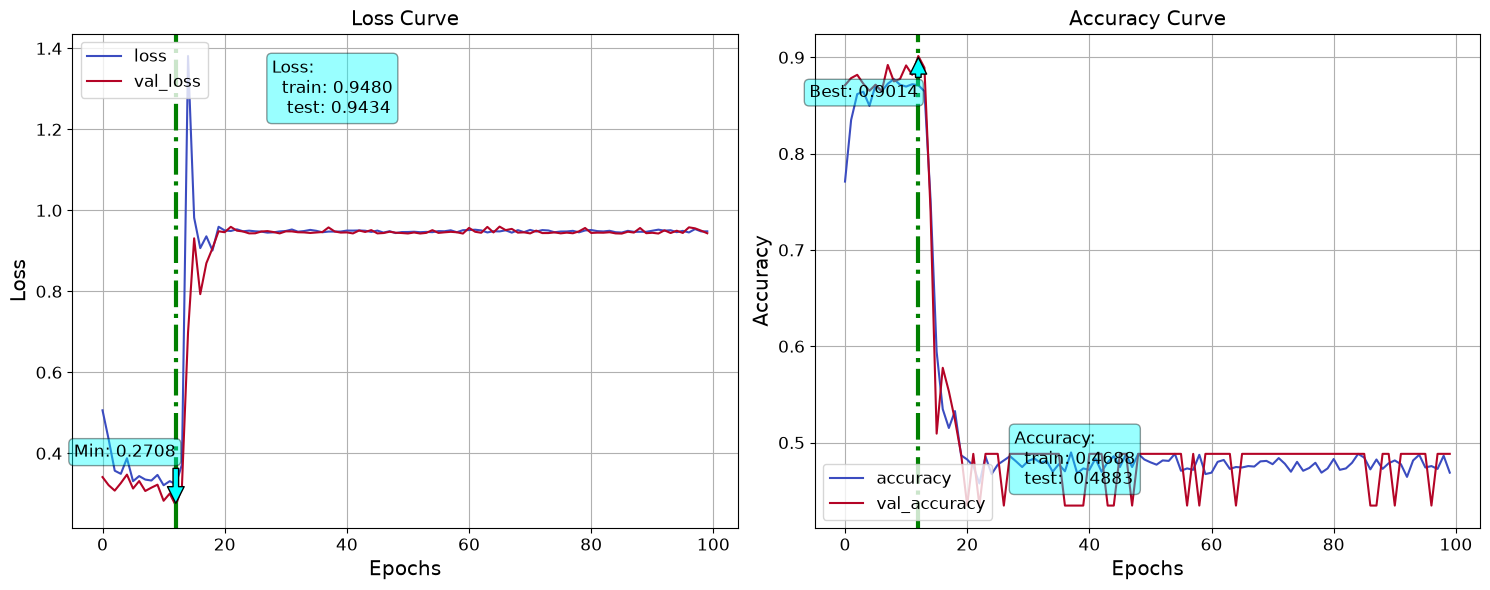

In [37]:

# Run the corrected function
fn_plot_tf_hist(loss_df)